# PIMA Diabetes Machine-Learning Project

Executed CRISP-DM analysis. The reusable implementation is in `data_pipeline.py` and `train.py`.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT/'train.py').exists(): ROOT=ROOT.parent
d=pd.read_csv(ROOT/'data/processed/cohort.csv')
summary=json.loads((ROOT/'artifacts/run_summary.json').read_text())
display(d.describe(include='all'))

,record_id,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome,split
count,768.000000,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000,768
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,460
mean,384.500000,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958,NaN
std,221.846794,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951,NaN
min,1.000000,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000,NaN
25%,192.750000,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000,NaN
50%,384.500000,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000,NaN
75%,576.250000,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000,NaN


## Data preparation

Invalid clinical zeros become missing. Imputation, scaling, engineering, and selection are fit inside training pipelines.

,model,split,accuracy,precision,recall,f1,roc_auc,average_precision,brier,n,positives,threshold
0,Prevalence baseline,train,0.6500,0.0000,0.0000,0.0000,0.5000,0.3500,0.2275,460,161,0.5
1,Prevalence baseline,validation,0.6494,0.0000,0.0000,0.0000,0.5000,0.3506,0.2277,154,54,0.5
2,Prevalence baseline,test,0.6558,0.0000,0.0000,0.0000,0.5000,0.3442,0.2257,154,53,0.5
3,Logistic / raw,train,0.8000,0.7674,0.6149,0.6828,0.8531,0.7413,0.1449,460,161,0.5
4,Logistic / raw,validation,0.7532,0.6538,0.6296,0.6415,0.8646,0.7525,0.1518,154,54,0.5
5,Logistic / raw,test,0.7338,0.6364,0.5283,0.5773,0.7932,0.6803,0.1740,154,53,0.5
6,Logistic / scaled,train,0.8000,0.7674,0.6149,0.6828,0.8538,0.7419,0.1444,460,161,0.5
7,Logistic / scaled,validation,0.7532,0.6538,0.6296,0.6415,0.8619,0.7491,0.1516,154,54,0.5
8,Logistic / scaled,test,0.7403,0.6512,0.5283,0.5833,0.7925,0.6806,0.1736,154,53,0.5
9,Logistic / engineered,train,0.8065,0.7609,0.6522,0.7023,0.8725,0.7755,0.1352,460,161,0.5


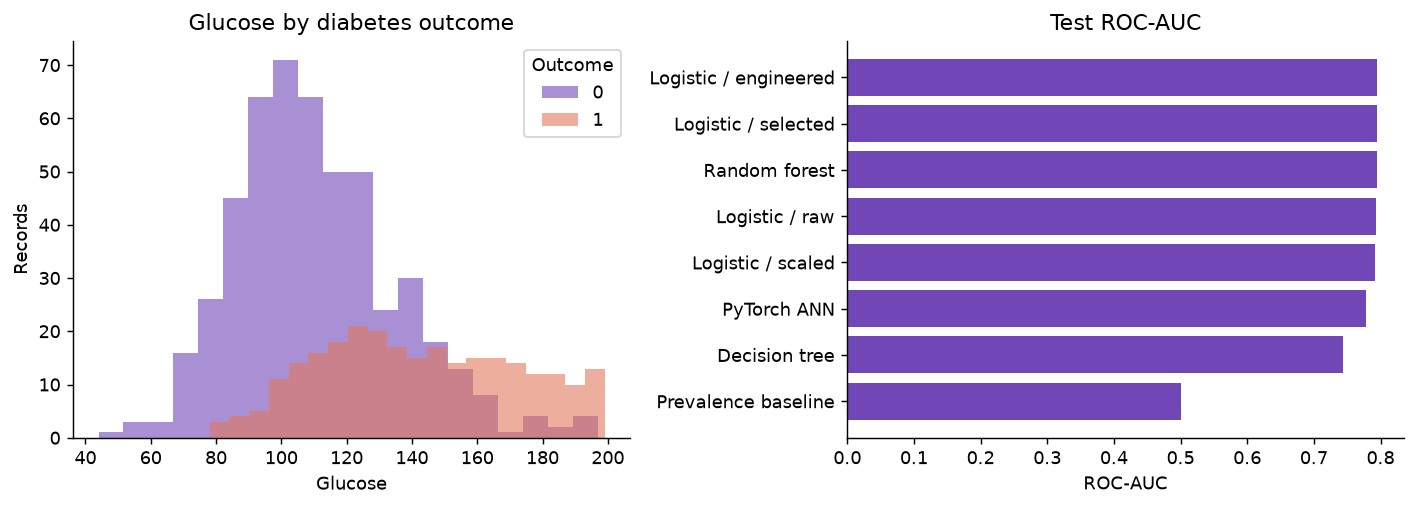

In [2]:
display(pd.read_csv(ROOT/'artifacts/classification_metrics.csv').round(4))
display(Image(filename=str(ROOT/'reports/figures/01_results.png')))

## Regression and neural network

BMI is excluded from regression inputs. The ANN uses 32 and 16 hidden units with dropout and early stopping.

,model,split,mae,mse,rmse,r2,n
0,Mean baseline,train,5.3263,46.9141,6.8494,0.0000,452
1,Mean baseline,validation,5.9129,51.7870,7.1963,-0.0066,154
2,Mean baseline,test,5.4164,46.8582,6.8453,-0.0028,151
3,Ridge,train,4.2088,29.3023,5.4132,0.3754,452
4,Ridge,validation,4.6895,36.3365,6.0280,0.2937,154
5,Ridge,test,3.8498,23.8807,4.8868,0.4889,151
6,Decision tree regressor,train,4.1801,30.2491,5.4999,0.3552,452
7,Decision tree regressor,validation,4.8596,38.4344,6.1996,0.2529,154
8,Decision tree regressor,test,4.6554,35.1004,5.9246,0.2488,151
9,Random forest regressor,train,2.8837,14.6862,3.8323,0.6870,452


,epoch,train_loss,validation_loss,train_accuracy,validation_accuracy
107,108,0.426719,0.447211,0.815217,0.759740
108,109,0.425967,0.447290,0.813043,0.759740
109,110,0.425225,0.447368,0.813043,0.766234
110,111,0.424508,0.447462,0.813043,0.766234
111,112,0.423803,0.447572,0.813043,0.766234


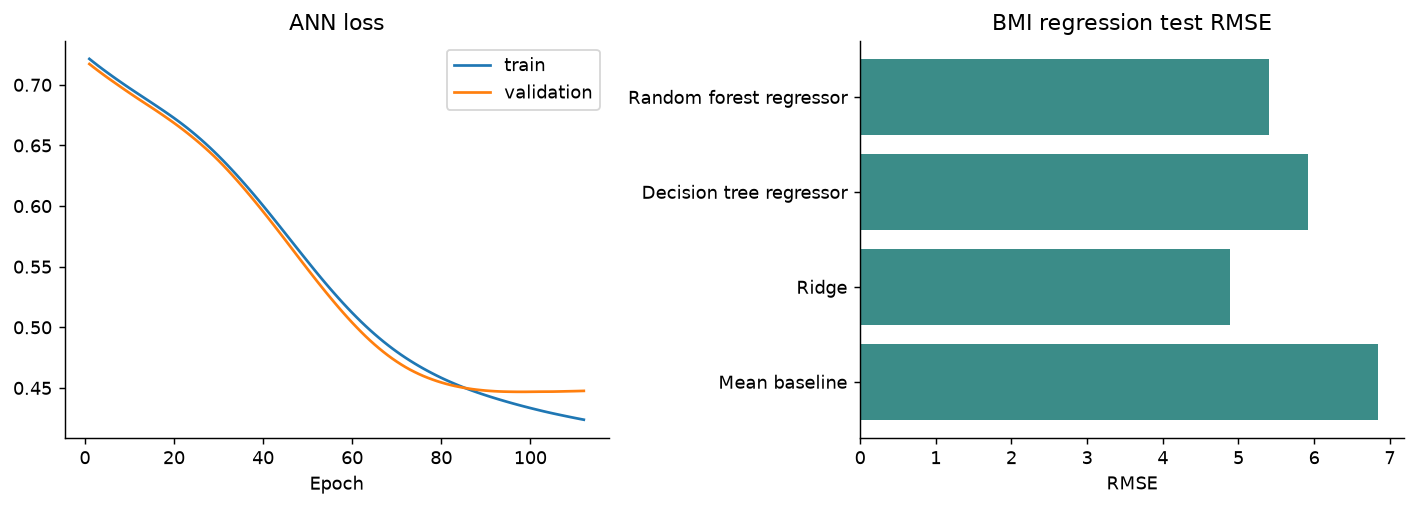

In [3]:
display(pd.read_csv(ROOT/'artifacts/regression_metrics.csv').round(4))
display(pd.read_csv(ROOT/'artifacts/ann_history.csv').tail())
display(Image(filename=str(ROOT/'reports/figures/02_learning_regression.png')))

## Feature experiments and conclusions

In [4]:
display(pd.read_csv(ROOT/'artifacts/permutation_importance.csv'))
display(pd.read_csv(ROOT/'artifacts/learning_curves.csv'))
display(Markdown((ROOT/'reports/REPORT.md').read_text(encoding='utf-8').split('## Discussion')[1]))

,feature,importance,std
0,glucose,0.122204,0.035117
1,bmi,0.046815,0.017338
2,age,0.023935,0.014164
3,diabetes_pedigree,0.006398,0.004339
4,pregnancies,0.003287,0.005311
5,skin_thickness,0.002815,0.002260
6,blood_pressure,0.001148,0.001518
7,insulin,-0.000287,0.004260


,model,n_train,split,roc_auc
0,Logistic / engineered,115,train,0.891473
1,Logistic / engineered,115,validation,0.824815
2,Random forest,115,train,0.974160
3,Random forest,115,validation,0.840185
4,Logistic / engineered,230,train,0.884305
5,Logistic / engineered,230,validation,0.839815
6,Random forest,230,train,0.972243
7,Random forest,230,validation,0.839444
8,Logistic / engineered,345,train,0.864928
9,Logistic / engineered,345,validation,0.837593




The ablation shows whether scaling, engineered features, or embedded selection changes generalization. Feature selection can simplify a model without guaranteeing higher performance. Learning curves compare training and validation behavior as the training sample grows. The ANN uses dropout and early stopping; its best checkpoint is epoch 97.

The dataset is small, historical, and population-specific. Missing measurements may not be missing at random. A random split does not test future or external populations. Real deployment would require broader data, external validation, calibration, subgroup evaluation, and clinical review.

## Conclusion

The project implements the complete required pipeline: cleaning, feature engineering, embedded selection, classification, regression, neural-network training, bias–variance diagnostics, and Streamlit visualization. Results support comparison of methods on this dataset only.

## References

- [PIMA dataset CSV](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv)
- [Dataset documentation](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.names)
- Local Machine Learning Labs 1 and 3 and project brief.
- [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [PyTorch optimization tutorial](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
